# Candidate cover pages: a sample to hand-label

Follow-up to `landscape_analysis.ipynb`, which found that landscape pages (about 5% of scans) are often pension file jackets, and that most of them fall in a tight size band. Here we:

1. turn that into an explicit **candidate-cover rule** (with tiers),
2. look at what it implies for file lengths per reel,
3. draw a **stratified random sample** (strong candidates, weaker candidates, and portrait controls),
4. download thumbnails and build a **self-contained HTML labeling page** plus a CSV template,
5. (after labeling) **score the rule** against your labels.

The sample is shown to you *blind*: the labeling page does not reveal which tier an image came from.

In [6]:
import json, base64, io
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image

Image.MAX_IMAGE_PIXELS = None
OUT = Path("labeling"); (OUT / "thumbs").mkdir(parents=True, exist_ok=True)
SEED = 20261105
N_STRONG, N_WEAK, N_PORTRAIT = 50, 40, 30   # sample sizes per tier

## 1. Load and derive features

In [7]:
df = pd.read_csv("nara_reel_tif_image_dimensions.csv")
parts = df.pageImageURL.str.extract(r"M804-(\d+)/M804-\d+-(\d+)")
df["reel"] = parts[0].astype(int)
df["page"] = parts[1].astype(int)
df = df.sort_values(["reel", "page"]).reset_index(drop=True)

df["aspect"] = df.width / df.height
df["megapixels"] = df.width * df.height / 1e6
df["landscape"] = df.width > df.height
df["pos_in_reel"] = df.groupby("reel").cumcount() + 1   # 1-based position (page numbers may have gaps)
print(len(df), "images")

75804 images


## 2. The candidate rule

Using the findings from the first notebook:

| tier | rule | intent |
|---|---|---|
| **A: strong** | landscape, 6000-6700 px wide, 4300-4700 px tall, aspect 1.38-1.47 | the "typical jacket" size cluster |
| **B: weak** | landscape, but not tier A | wide interior documents, odd-sized jackets, reel front matter |
| **C: portrait** | everything else | control group: how many covers does the rule miss? |

Tier A's aspect bounds are just the observed spread of that size band (1.33-1.49) trimmed to where the bulk sits.

In [8]:
band = df.width.between(6000, 6700) & df.height.between(4300, 4700)
df["tier"] = "C"
df.loc[df.landscape, "tier"] = "B"
df.loc[df.landscape & band & df.aspect.between(1.38, 1.47), "tier"] = "A"

summary = df.tier.value_counts().sort_index().rename("images").to_frame()
summary["percent"] = (summary.images / len(df) * 100).round(2)
summary

,images,percent
tier,,
A,2362,3.12
B,1369,1.81
C,72073,95.08


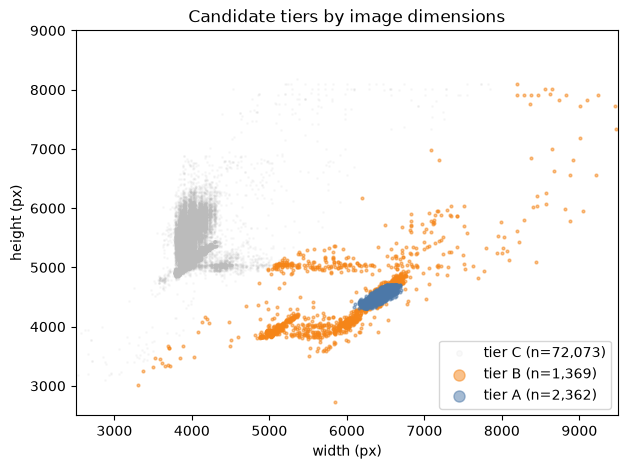

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
for t, c, s, a in [("C", "#bbbbbb", 1, .08), ("B", "#f58518", 4, .5), ("A", "#4c78a8", 4, .5)]:
    d = df[df.tier == t]
    ax.scatter(d.width, d.height, s=s, alpha=a, color=c, label=f"tier {t} (n={len(d):,})")
ax.set_xlim(2500, 9500); ax.set_ylim(2500, 9000)
ax.set_xlabel("width (px)"); ax.set_ylabel("height (px)"); ax.legend(markerscale=4)
ax.set_title("Candidate tiers by image dimensions")
plt.show()

## 3. What does tier A imply about reel structure?

If tier A were a perfect cover detector, the distance between consecutive tier-A pages would be the file length. We can't check that yet, but we can see whether the numbers are plausible, and whether tier A cleans up the short-gap problem noted in the first notebook (26% of landscape gaps were <= 3 pages).

       all landscape  tier A only
count         3657.0       2288.0
mean            20.2         31.4
std             20.5         28.3
min              1.0          1.0
25%              3.0         14.0
50%             16.0         24.0
75%             29.0         42.0
max            199.0        258.0
Gaps <= 3 pages: all landscape 26%, tier A 15%


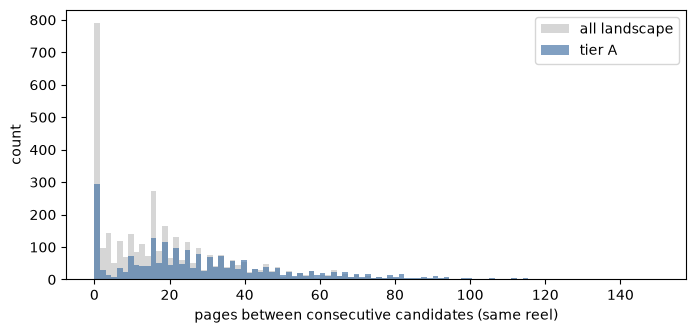

In [10]:
A = df[df.tier == "A"]
gapsA = A.groupby("reel").pos_in_reel.diff().dropna()
gapsAll = df[df.landscape].groupby("reel").pos_in_reel.diff().dropna()
print(pd.DataFrame({"all landscape": gapsAll.describe(), "tier A only": gapsA.describe()}).round(1))
print(f"Gaps <= 3 pages: all landscape {(gapsAll<=3).mean():.0%}, tier A {(gapsA<=3).mean():.0%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(gapsAll, bins=100, range=(0, 150), alpha=.6, label="all landscape", color="#bbbbbb")
ax.hist(gapsA, bins=100, range=(0, 150), alpha=.7, label="tier A", color="#4c78a8")
ax.set_xlabel("pages between consecutive candidates (same reel)"); ax.set_ylabel("count"); ax.legend()
plt.show()

In [11]:
# Where do candidates sit relative to the start of the reel? (Reel front matter may look like covers.)
first = df[df.pos_in_reel <= 5].groupby("pos_in_reel").tier.value_counts().unstack(fill_value=0)
first["pct_A"] = (first.A / first.sum(axis=1) * 100).round(1)
first["pct_B"] = (first.B / (first.A + first.B + first.C) * 100).round(1)
first

tier,A,B,C,pct_A,pct_B
pos_in_reel,,,,,
1,0,41,33,0.0,55.4
2,2,53,19,2.7,71.6
3,0,4,70,0.0,5.4
4,0,0,74,0.0,0.0
5,0,0,74,0.0,0.0


Positions 1 and 2 of each reel are landscape 55% and 72% of the time (vs ~5% overall), almost all tier B, so those are probably microfilm targets or title frames rather than pension jackets. From position 3 on the rate is normal. The sample therefore includes some images from the first few pages of reels on purpose (below), so you can label them as `front_matter` and we can exclude that region from the rule.

## 4. Draw the sample

Stratified random sample: tiers A, B and C drawn independently. Within each tier, a fixed share comes from the first 5 positions of a reel (capped by what exists), so front matter gets seen. Sampling is seeded, so re-running reproduces the same sample.

In [12]:
rng = np.random.default_rng(SEED)

def draw(tier, n, n_front=0):
    pool = df[df.tier == tier]
    front = pool[pool.pos_in_reel <= 5]
    rest = pool[pool.pos_in_reel > 5]
    f = front.sample(min(n_front, len(front)), random_state=int(rng.integers(1e9)))
    r = rest.sample(n - len(f), random_state=int(rng.integers(1e9)))
    return pd.concat([f, r])

sample = pd.concat([draw("A", N_STRONG, 8), draw("B", N_WEAK, 8), draw("C", N_PORTRAIT, 4)])
# shuffle so the order carries no information about tier, then assign neutral ids
sample = sample.sample(frac=1, random_state=SEED).reset_index(drop=True)
sample["sample_id"] = [f"s{i:03d}" for i in range(len(sample))]
print(sample.tier.value_counts().sort_index().to_dict(), "| in first 5 positions:", (sample.pos_in_reel <= 5).sum())
sample[["sample_id", "reel", "page", "pos_in_reel", "width", "height", "aspect", "tier"]].head()

{'A': 50, 'B': 40, 'C': 30} | in first 5 positions: 14


,sample_id,reel,page,pos_in_reel,width,height,aspect,tier
0,s000,1864,250,250,6377,4409,1.446360,A
1,s001,1932,147,147,6297,4473,1.407780,A
2,s002,1795,550,550,3897,5017,0.776759,C
3,s003,1813,487,487,3881,5049,0.768667,C
4,s004,1830,985,985,6537,4617,1.415854,A


## 5. Fetch thumbnails

The TIFFs are about 30 MB each, so the whole file has to be downloaded to decode it (the earlier header-only trick doesn't help here). Each one is downscaled to 1000 px on its long side and cached in `labeling/thumbs/`; re-running only fetches what's missing.

In [13]:
THUMB = 1000

def fetch_thumb(row):
    path = OUT / "thumbs" / f"{row.sample_id}.jpg"
    if path.exists():
        return row.sample_id, None
    for attempt in range(4):
        try:
            r = requests.get(row.pageImageURL, timeout=120)
            r.raise_for_status()
            im = Image.open(io.BytesIO(r.content))
            im.load()
            im = im.convert("L") if im.mode in ("1", "L", "I;16") else im.convert("RGB")
            im.thumbnail((THUMB, THUMB), Image.LANCZOS)
            im.save(path, quality=80)
            return row.sample_id, None
        except Exception as e:
            err = repr(e)
    return row.sample_id, err

with ThreadPoolExecutor(6) as pool:
    results = list(pool.map(fetch_thumb, sample.itertuples()))
failed = [r for r in results if r[1]]
print(f"{len(results) - len(failed)} ok, {len(failed)} failed", failed[:3])

120 ok, 0 failed []


## 6. Build the labeling page and CSV

Outputs (in `labeling/`):

- `label.html`: open in a browser. Self-contained (thumbnails embedded). One image at a time; keys **c** = cover, **f** = front_matter, **n** = not_cover, **u** = unsure, **←/→** to move. Progress autosaves in the browser; **Export CSV** downloads `labels.csv`.
- `labels_template.csv`: the same ids with a blank `label` column, if you'd rather fill in a spreadsheet (opening `thumbs/<sample_id>.jpg` as needed).
- `sample_key.csv`: the hidden features (tier, dimensions). Don't peek until you've labeled.

Label meanings: `cover` = the jacket / first page of a pension file; `front_matter` = microfilm target, title frame or index at the start of a reel; `not_cover` = any other page; `unsure` = can't tell from the thumbnail (use the full-res link).

In [14]:
LABELS = ["cover", "front_matter", "not_cover", "unsure"]
ok = sample[sample.sample_id.map(lambda s: (OUT / "thumbs" / f"{s}.jpg").exists())]

items = []
for r in ok.itertuples():
    b64 = base64.b64encode((OUT / "thumbs" / f"{r.sample_id}.jpg").read_bytes()).decode()
    items.append({"id": r.sample_id, "reel": int(r.reel), "page": int(r.page), "url": r.pageImageURL, "img": b64})

TEMPLATE = r'''<!doctype html><html lang="en"><meta charset="utf-8"><title>Cover labeling</title>
<style>
 body{font:15px system-ui,sans-serif;margin:0;background:#1d1d20;color:#eee;display:flex;flex-direction:column;height:100vh}
 header,footer{padding:8px 16px;background:#2a2a2e;display:flex;gap:12px;align-items:center;flex-wrap:wrap}
 main{flex:1;min-height:0;display:flex;justify-content:center;align-items:center;padding:8px}
 main img{max-width:100%;max-height:100%;object-fit:contain;background:#000}
 button{font:inherit;padding:6px 14px;border-radius:6px;border:1px solid #666;background:#38383d;color:#eee;cursor:pointer}
 button.sel{background:#4c78a8;border-color:#8fb4dd}
 input{font:inherit;padding:5px;width:22em;border-radius:6px;border:1px solid #666;background:#18181b;color:#eee}
 a{color:#8fb4dd} .sp{flex:1} kbd{background:#444;border-radius:3px;padding:0 5px}
</style>
<header><b id="pos"></b><span id="meta"></span><a id="full" target="_blank" rel="noopener">open full-res TIFF</a>
 <span class="sp"></span><span id="done"></span><button id="export">Export CSV</button></header>
<main><img id="im"></main>
<footer id="btns"></footer>
<script>
const ITEMS = __ITEMS__, LABELS = __LABELS__, KEYS = {c:"cover", f:"front_matter", n:"not_cover", u:"unsure"};
const KEY = "cover-labels-v1";
let st = {}; try { st = JSON.parse(localStorage.getItem(KEY)) || {}; } catch(e) {}
let i = 0;
const $ = id => document.getElementById(id);
const save = () => { try { localStorage.setItem(KEY, JSON.stringify(st)); } catch(e) {} };
function show(){
  const it = ITEMS[i], s = st[it.id] || {};
  $("pos").textContent = `${i+1} / ${ITEMS.length}`;
  $("meta").textContent = `${it.id}  reel ${it.reel}  page ${it.page}`;
  $("full").href = it.url;
  $("im").src = "data:image/jpeg;base64," + it.img;
  $("done").textContent = `${Object.values(st).filter(x=>x.label).length} labeled`;
  $("btns").innerHTML = "";
  for (const [k,l] of Object.entries(KEYS)) {
    const b = document.createElement("button"); b.textContent = `${l} [${k}]`;
    if (s.label === l) b.className = "sel";
    b.onclick = () => set(l); $("btns").appendChild(b);
  }
  const n = document.createElement("input"); n.placeholder = "notes (optional)"; n.value = s.notes || "";
  n.oninput = () => { st[it.id] = {...(st[it.id]||{}), notes: n.value}; save(); };
  n.onkeydown = e => e.stopPropagation();
  $("btns").appendChild(n);
}
function set(l){ st[ITEMS[i].id] = {...(st[ITEMS[i].id]||{}), label: l}; save(); if (i < ITEMS.length-1) i++; show(); }
function go(d){ i = Math.max(0, Math.min(ITEMS.length-1, i+d)); show(); }
document.onkeydown = e => { if (KEYS[e.key]) set(KEYS[e.key]); else if (e.key==="ArrowRight") go(1); else if (e.key==="ArrowLeft") go(-1); };
$("export").onclick = () => {
  const q = v => '"' + String(v||"").replace(/"/g,'""') + '"';
  const rows = ["sample_id,reel,page,label,notes"].concat(ITEMS.map(it => {
    const s = st[it.id] || {}; return [it.id, it.reel, it.page, s.label||"", q(s.notes)].join(","); }));
  const a = document.createElement("a");
  a.href = URL.createObjectURL(new Blob([rows.join("\n")], {type:"text/csv"})); a.download = "labels.csv"; a.click();
};
const firstTodo = ITEMS.findIndex(it => !(st[it.id]||{}).label); i = firstTodo < 0 ? 0 : firstTodo; show();
</script></html>'''
html = TEMPLATE.replace("__ITEMS__", json.dumps(items)).replace("__LABELS__", json.dumps(LABELS))
(OUT / "label.html").write_text(html)

ok[["sample_id", "reel", "page", "pageImageURL"]].assign(label="", notes="").to_csv(OUT / "labels_template.csv", index=False)
ok[["sample_id", "reel", "page", "pos_in_reel", "width", "height", "aspect", "megapixels", "tier"]].to_csv(OUT / "sample_key.csv", index=False)
print(f"{len(items)} items, label.html = {(OUT / 'label.html').stat().st_size/1e6:.1f} MB")

120 items, label.html = 14.8 MB


## 7. After labeling: score the rule

Save the exported file as `labeling/labels.csv`. This section is skipped until it exists. Tier-C labeled `cover` are covers the rule misses; tier-A labeled anything else are false positives. Because tiers were sampled at different rates, **per-tier rates are the honest numbers**; the pooled estimate re-weights each tier by its true population size.

In [15]:
labels_path = OUT / "labels.csv"
if not labels_path.exists():
    print("No labels yet. Label the sample in labeling/label.html, export, and save as", labels_path)
else:
    lab = pd.read_csv(labels_path).merge(pd.read_csv(OUT / "sample_key.csv"), on=["sample_id", "reel", "page"])
    lab = lab[lab.label.notna() & (lab.label != "")]
    print(len(lab), "labeled")
    ct = pd.crosstab(lab.tier, lab.label)
    ct["n"] = ct.sum(axis=1)
    display(ct)

    # Per-tier cover rate, re-weighted by population size to estimate overall precision / recall
    pop = df.tier.value_counts()
    rate = (lab.assign(is_cover=lab.label == "cover").groupby("tier").is_cover.mean())
    est_covers = (rate * pop.reindex(rate.index))
    print("Estimated true covers per tier (rate x population):")
    print(est_covers.round(0).to_string())
    total = est_covers.sum()
    for name, tiers in [("tier A", ["A"]), ("tier A+B", ["A", "B"])]:
        tp = est_covers.reindex(tiers).sum(); flagged = pop.reindex(tiers).sum()
        print(f"{name}: precision ~{tp/flagged:.0%}, recall ~{tp/total:.0%}  (of ~{total:,.0f} covers overall)")
    print("Tier C sample has only", (lab.tier == "C").sum(), "labels, so the recall estimate is rough if few covers show up there.")

120 labeled


label,cover,front_matter,not_cover,n
tier,,,,
A,48,2,0,50
B,6,8,26,40
C,0,7,23,30


Estimated true covers per tier (rate x population):
tier
A    2268.0
B     205.0
C       0.0
tier A: precision ~96%, recall ~92%  (of ~2,473 covers overall)
tier A+B: precision ~66%, recall ~100%  (of ~2,473 covers overall)
Tier C sample has only 30 labels, so the recall estimate is rough if few covers show up there.


## Summary

**Question:** can image dimensions alone find candidate cover cards (file jackets) for splitting reels?

**Rule.** Tier A = landscape, 6000-6700 x 4300-4700 px, aspect 1.38-1.47 (2,362 pages). Tier B = other landscape pages (1,369). Tier C = portrait (72,073).

**Hand-labeled sample (120 pages, blind):**

| Tier | Labeled | Cover | Front matter | Not cover |
|---|---|---|---|---|
| A | 50 | 48 | 2 | 0 |
| B | 40 | 6 | 8 | 26 |
| C | 30 | 0 | 7 | 23 |

**Findings**
- **Tier A is a reliable cover detector.** 48/50 were covers (precision ~96%, roughly 86-99% given the sample size); the 2 misses were reel front matter. That gives about 2,270 file boundaries, ~30 per reel.
- **Tier B is mostly noise.** Only ~15% were covers. Including it drops precision to ~66%, so leave it out unless it can be refined. It holds roughly 200 covers, probably jackets with unusual dimensions.
- **Recall is not established.** The ~92% estimate rests on finding 0 covers in 30 portrait pages. Portrait pages are 95% of the data, so a small miss rate would still mean hundreds of missed covers. Treat 92% as an upper bound. The portrait sample also oversampled reel starts on purpose, so its front-matter count is not a rate.
- **Reel front matter** (targets, title frames) sits mostly at positions 1-2, is mostly landscape, and some is portrait.

**Next steps**
1. Exclude the first 2 positions of each reel from tier A to drop front-matter false positives.
2. Compare the 6 tier B covers with the 26 non-covers; if dimensions separate them, widen the rule.
3. Test recall directly: find reels with long gaps (>100 pages) between tier A hits and label the pages in those gaps.
4. Use the `extractedText` column in the source CSV as a second, independent cover signal.